**Célula 1 – setup e carregar os modelos:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, DIMS, CLASS_NAMES, get_splits
from src.representation import (fit_pca, pca_project, pca_reconstruct,
                                load_autoencoder, ae_encode, ae_decode)

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

pca = fit_pca(X_train)                                                    
aes = {d: load_autoencoder(d, f"models/ae_{d}.pt") for d in DIMS}         

def reconstruct(method, d, X):
    if method == "PCA":
        return pca_reconstruct(pca, pca_project(pca, X, d))
    return ae_decode(aes[d], ae_encode(aes[d], X))

**Célula 2 – escolher um exemplo de teste por classe:**

In [2]:
rng = np.random.default_rng(SEED)
example_idx = np.array([rng.choice(np.where(y_test == c)[0]) for c in range(10)])
X_examples = X_test[example_idx]

**Célula 3 – painel 1: as 10 classes, com 8 e 32 dimensões:**

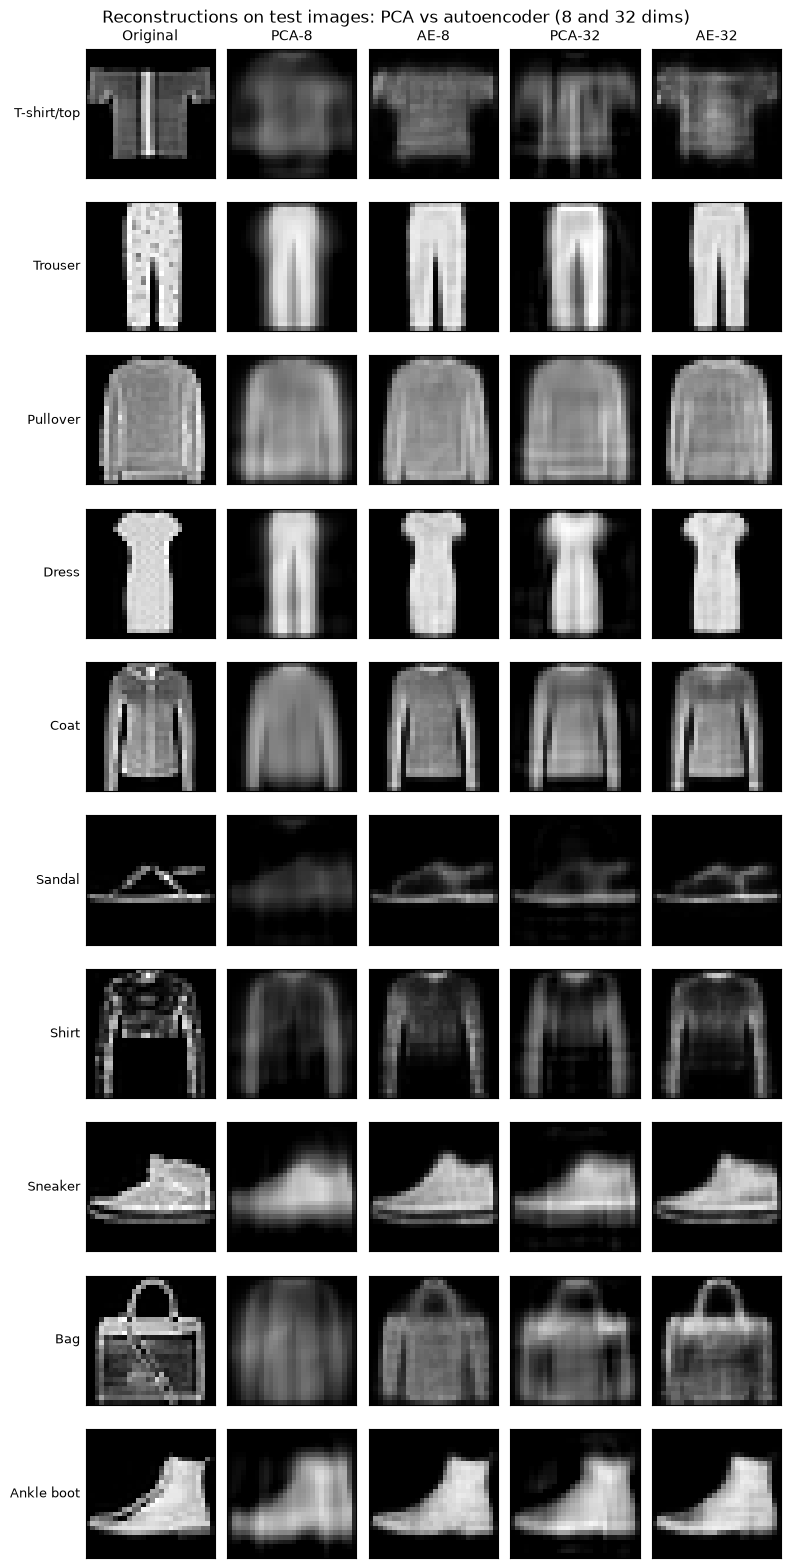

In [3]:
cols = [("Original", None, None),
        ("PCA-8", "PCA", 8), ("AE-8", "AE", 8),
        ("PCA-32", "PCA", 32), ("AE-32", "AE", 32)]

images = {title: (X_examples if method is None else reconstruct(method, d, X_examples))
          for title, method, d in cols}

fig, axes = plt.subplots(10, len(cols), figsize=(len(cols) * 1.6, 10 * 1.6))
for r in range(10):
    for c, (title, _, _) in enumerate(cols):
        ax = axes[r, c]
        ax.imshow(images[title][r].reshape(28, 28), cmap="gray", vmin=0, vmax=1)  # mesma escala em todas
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(title, fontsize=10)
    axes[r, 0].set_ylabel(CLASS_NAMES[r], fontsize=9, rotation=0, ha="right", va="center")

plt.suptitle("Reconstructions on test images: PCA vs autoencoder (8 and 32 dims)")
plt.tight_layout()
plt.savefig("results/figures/08_reconstruction_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 4 – painel 2: evolução com a dimensão (3 exemplos):**

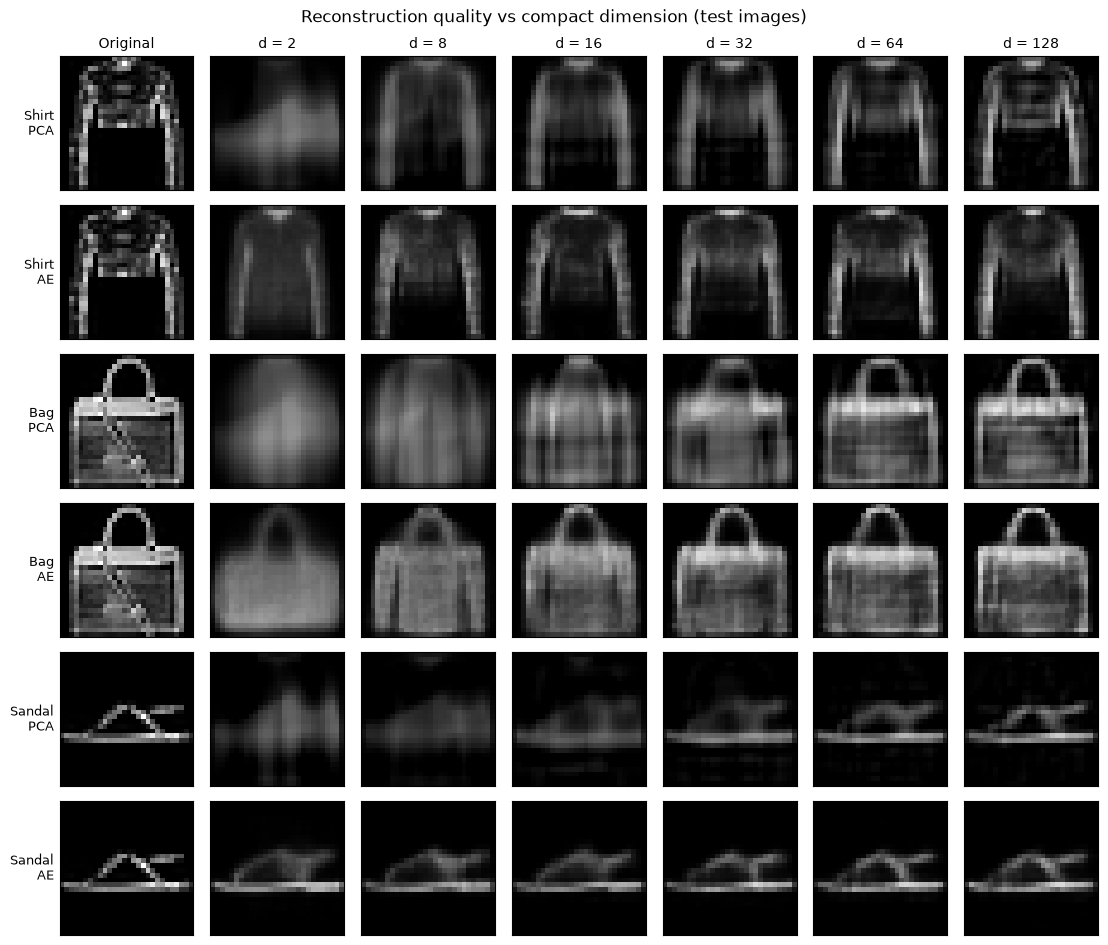

In [4]:
chosen_classes = [6, 8, 5]          
fig, axes = plt.subplots(len(chosen_classes) * 2, len(DIMS) + 1,
                         figsize=((len(DIMS) + 1) * 1.6, len(chosen_classes) * 2 * 1.6))

for k, c in enumerate(chosen_classes):
    x = X_examples[c:c + 1]                              
    for m, method in enumerate(["PCA", "AE"]):
        row = 2 * k + m
        axes[row, 0].imshow(x.reshape(28, 28), cmap="gray", vmin=0, vmax=1)  
        axes[row, 0].set_ylabel(f"{CLASS_NAMES[c]}\n{method}", fontsize=9, rotation=0, ha="right", va="center")
        for j, d in enumerate(DIMS):
            axes[row, j + 1].imshow(reconstruct(method, d, x).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            if row == 0:
                axes[row, j + 1].set_title(f"d = {d}", fontsize=10)
    axes[0, 0].set_title("Original", fontsize=10)

for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Reconstruction quality vs compact dimension (test images)")
plt.tight_layout()
plt.savefig("results/figures/08_reconstruction_by_dim.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 5 – tabela final: MSE no teste (geral e por classe):**

In [5]:
rows = []
for d in DIMS:
    rows.append({"dim": d,
                 "pca_test_mse": np.mean((X_test - reconstruct("PCA", d, X_test)) ** 2),
                 "ae_test_mse": np.mean((X_test - reconstruct("AE", d, X_test)) ** 2)})
test_mse = pd.DataFrame(rows)
print(test_mse.round(5).to_string(index=False))
test_mse.to_csv("results/tables/08_reconstruction_test_mse.csv", index=False)

d = 32
err_pca = np.mean((X_test - reconstruct("PCA", d, X_test)) ** 2, axis=1)   
err_ae = np.mean((X_test - reconstruct("AE", d, X_test)) ** 2, axis=1)
per_class = pd.DataFrame({
    "class": CLASS_NAMES,
    "pca_mse_32": [err_pca[y_test == c].mean() for c in range(10)],
    "ae_mse_32": [err_ae[y_test == c].mean() for c in range(10)],
}).sort_values("ae_mse_32", ascending=False)                                 
print(per_class.round(5).to_string(index=False))
per_class.to_csv("results/tables/08_reconstruction_per_class_32.csv", index=False)

 dim  pca_test_mse  ae_test_mse
   2       0.04610      0.02400
   8       0.02661      0.01251
  16       0.02045      0.00995
  32       0.01515      0.00803
  64       0.01037      0.00742
 128       0.00632      0.00696
      class  pca_mse_32  ae_mse_32
        Bag     0.02237    0.01349
     Sandal     0.02261    0.01251
      Shirt     0.01316    0.00845
 Ankle boot     0.01781    0.00776
T-shirt/top     0.01274    0.00751
      Dress     0.01382    0.00729
   Pullover     0.01267    0.00725
       Coat     0.01304    0.00678
    Sneaker     0.01265    0.00581
    Trouser     0.01058    0.00350
